**Plant disease detection**

In [ ]:
# TensorFlow: CNN model banane aur train karne ke liye
# TensorFlow Datasets: PlantVillage dataset load karne ke liye
# Scikit-learn: Model evaluation ke liye
# Seaborn: Attractive graphs aur confusion matrix ke liye

!pip -q install tensorflow-datasets scikit-learn seaborn gradio

In [ ]:
# Required packages install/update karna
%pip install -q importlib-resources tensorflow-datasets

In [ ]:
# Data processing aur numerical calculations
import os
import json
import time
import numpy as np
import pandas as pd

# Graphs aur images display karne ke liye
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display

# Deep learning framework
import tensorflow as tf
import tensorflow_datasets as tfds

# Model evaluation
from sklearn.metrics import classification_report, confusion_matrix

# Google Colab upload/download functionality
from google.colab import files

# Graphs ka appearance improve karna
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow version: 2.21.0
GPU available: True


In [ ]:
# Missing package install kar rahe hain
!pip install -q importlib-resources

# TensorFlow Datasets ko bhi update kar rahe hain
!pip install -q --upgrade tensorflow-datasets

In [ ]:
# Python aur installed packages ki versions check karna
import sys

print("Python version:", sys.version)

# Missing package check karna
try:
    import importlib_resources
    print("importlib_resources: Installed")
except ImportError as e:
    print("Package issue:", e)

# TensorFlow Datasets ki version check karna
import tensorflow_datasets as tfds
print("TFDS version:", tfds.__version__)

Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
importlib_resources: Installed
TFDS version: 4.9.10


Download and load dataset

In [ ]:
# Hugging Face dataset aur image processing libraries
%pip install -q datasets pillow

In [ ]:
# PlantVillage dataset load karna
# Dataset mein 38 classes hain.
# class_label text mein hai aur class_idx numeric label hai.
# Original train/test split ko preserve karenge.


import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import json
import os
import random

from datasets import load_dataset
from sklearn.model_selection import train_test_split

# Fixed seed se results reproducible rakhna
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Hugging Face cache se dataset load hoga agar pehle download hai
hf_dataset = load_dataset(
    "geraldmc/plantvillage-full",
    revision="v0.1.0",
    split="train"
)

print("Total images:", len(hf_dataset))

# Har numeric class index ka correct disease name map karna
label_map = {}

for idx, name in zip(
    hf_dataset["class_idx"],
    hf_dataset["class_label"]
):
    label_map[int(idx)] = name

# Labels ko index order mein rakhna
class_names = [
    label_map[i] for i in sorted(label_map.keys())
]
num_classes = len(class_names)

print("Total disease classes:", num_classes)

for i, name in enumerate(class_names):
    print(i, ":", name)

# Dataset ke existing train aur test groups alag karna
# Is se original held-out test set preserve rahega
train_pool = hf_dataset.filter(
    lambda row: row["split"] == "train"
)

test_data = hf_dataset.filter(
    lambda row: row["split"] == "test"
)

# Training pool ke 10% ko validation ke liye rakhna
# Overall dataset ka approximately 72% train,
# 8% validation aur 20% test banega
all_indices = np.arange(len(train_pool))
all_labels = np.array(train_pool["class_idx"])

train_indices, val_indices = train_test_split(
    all_indices,
    test_size=0.10,
    random_state=SEED,
    stratify=all_labels
)

train_data = train_pool.select(train_indices.tolist())
val_data = train_pool.select(val_indices.tolist())

print("\nTraining images:", len(train_data))
print("Validation images:", len(val_data))
print("Testing images:", len(test_data))
print("\nDataset loading complete!")


README.md:   0%|          | 0.00/549 [00:00<?, ?B/s]

Generating train split:   0%|          | 0/54304 [00:00<?, ? examples/s]

Total images: 54304
Total disease classes: 38
0 : Apple___Apple_scab
1 : Apple___Black_rot
2 : Apple___Cedar_apple_rust
3 : Apple___healthy
4 : Blueberry___healthy
5 : Cherry_(including_sour)___Powdery_mildew
6 : Cherry_(including_sour)___healthy
7 : Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
8 : Corn_(maize)___Common_rust_
9 : Corn_(maize)___Northern_Leaf_Blight
10 : Corn_(maize)___healthy
11 : Grape___Black_rot
12 : Grape___Esca_(Black_Measles)
13 : Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
14 : Grape___healthy
15 : Orange___Haunglongbing_(Citrus_greening)
16 : Peach___Bacterial_spot
17 : Peach___healthy
18 : Pepper,_bell___Bacterial_spot
19 : Pepper,_bell___healthy
20 : Potato___Early_blight
21 : Potato___Late_blight
22 : Potato___healthy
23 : Raspberry___healthy
24 : Soybean___healthy
25 : Squash___Powdery_mildew
26 : Strawberry___Leaf_scorch
27 : Strawberry___healthy
28 : Tomato___Bacterial_spot
29 : Tomato___Early_blight
30 : Tomato___Late_blight
31 : Tomato___Leaf_Mold


Filter:   0%|          | 0/54304 [00:00<?, ? examples/s]

Filter:   0%|          | 0/54304 [00:00<?, ? examples/s]


Training images: 39020
Validation images: 4336
Testing images: 10948

Dataset loading complete!


Sample images display karna

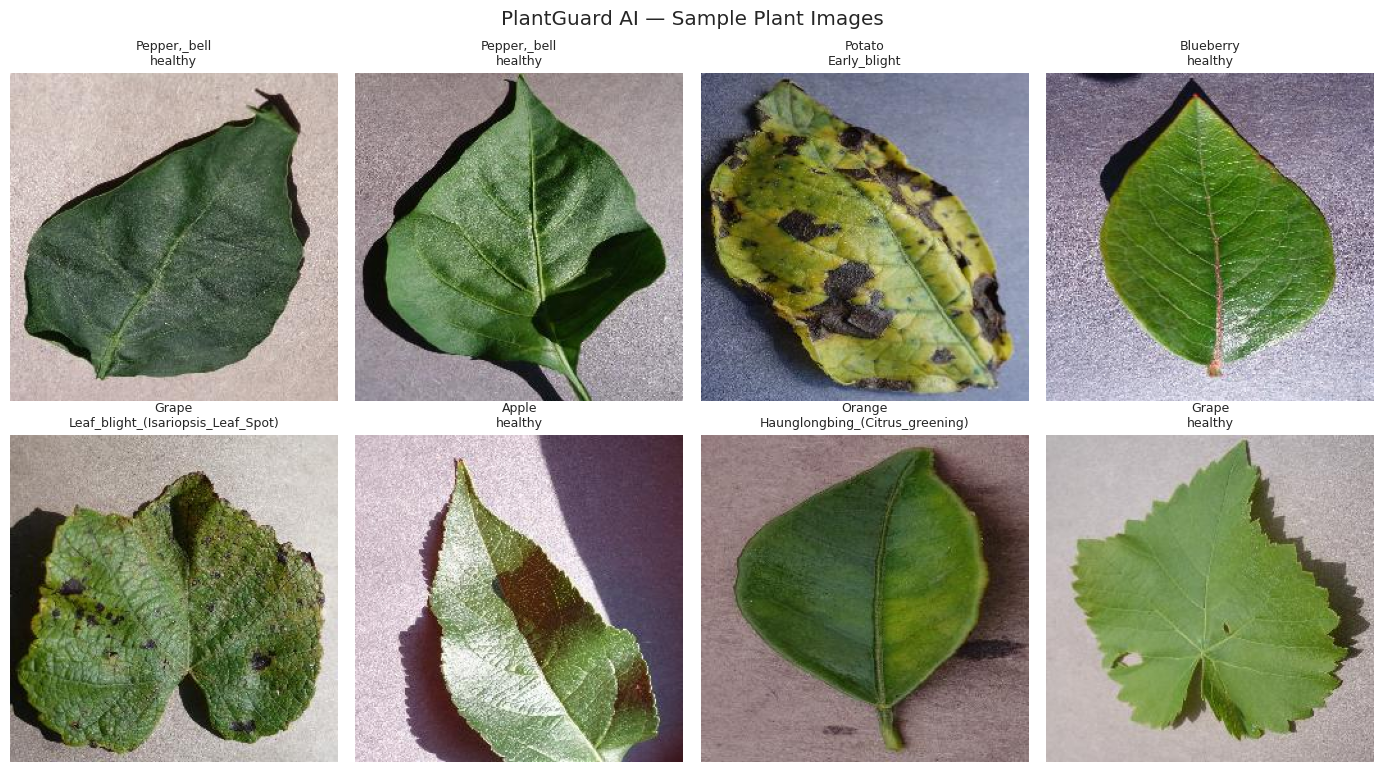

In [ ]:
# Dataset ki sample images dekhna
# Is se verify hoga ke images aur disease labels correct hain.

plt.figure(figsize=(14, 8))

for i in range(8):
    sample = train_data[i]

    image = sample["image"].convert("RGB")
    label = int(sample["class_idx"])

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(
        class_names[label].replace("___", "\n"),
        fontsize=9
    )
    plt.axis("off")

plt.suptitle("PlantGuard AI — Sample Plant Images")
plt.tight_layout()
plt.show()


Images preprocess karna

In [ ]:
# Images ko TensorFlow format mein convert karna
# Image size 160 x 160 hogi aur pixel values 0 se 1 hongi.


IMAGE_SIZE = 160
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def create_tf_dataset(source_data):
    # Dataset ke images aur labels TensorFlow ko provide karna
    def image_generator():
        for row in source_data:
            image = row["image"].convert("RGB")

            # Dataset images 256 x 256 hain
            image = image.resize((256, 256))

            image_array = np.asarray(
                image,
                dtype=np.uint8
            )

            label = np.int32(row["class_idx"])

            yield image_array, label

    output_signature = (
        tf.TensorSpec(
            shape=(256, 256, 3),
            dtype=tf.uint8
        ),
        tf.TensorSpec(
            shape=(),
            dtype=tf.int32
        )
    )

    return tf.data.Dataset.from_generator(
        image_generator,
        output_signature=output_signature
    )

# Images resize aur normalize karna
def preprocess_image(image, label):
    image = tf.image.resize(
        image,
        (IMAGE_SIZE, IMAGE_SIZE)
    )

    # Pixel values ko 0–1 range mein convert karna
    image = tf.cast(image, tf.float32) / 255.0

    return image, label

# Training dataset create karna
ds_train = create_tf_dataset(train_data)
ds_train = ds_train.map(
    preprocess_image,
    num_parallel_calls=AUTOTUNE
)
ds_train = ds_train.shuffle(
    2000,
    seed=SEED
).batch(BATCH_SIZE).prefetch(AUTOTUNE)

# Validation dataset create karna
ds_val = create_tf_dataset(val_data)
ds_val = ds_val.map(
    preprocess_image,
    num_parallel_calls=AUTOTUNE
)
ds_val = ds_val.batch(BATCH_SIZE).prefetch(AUTOTUNE)

# Testing dataset create karna
ds_test = create_tf_dataset(test_data)
ds_test = ds_test.map(
    preprocess_image,
    num_parallel_calls=AUTOTUNE
)
ds_test = ds_test.batch(BATCH_SIZE).prefetch(AUTOTUNE)

print("Training, validation and testing pipelines ready!")


Training, validation and testing pipelines ready!


Class distribution graph

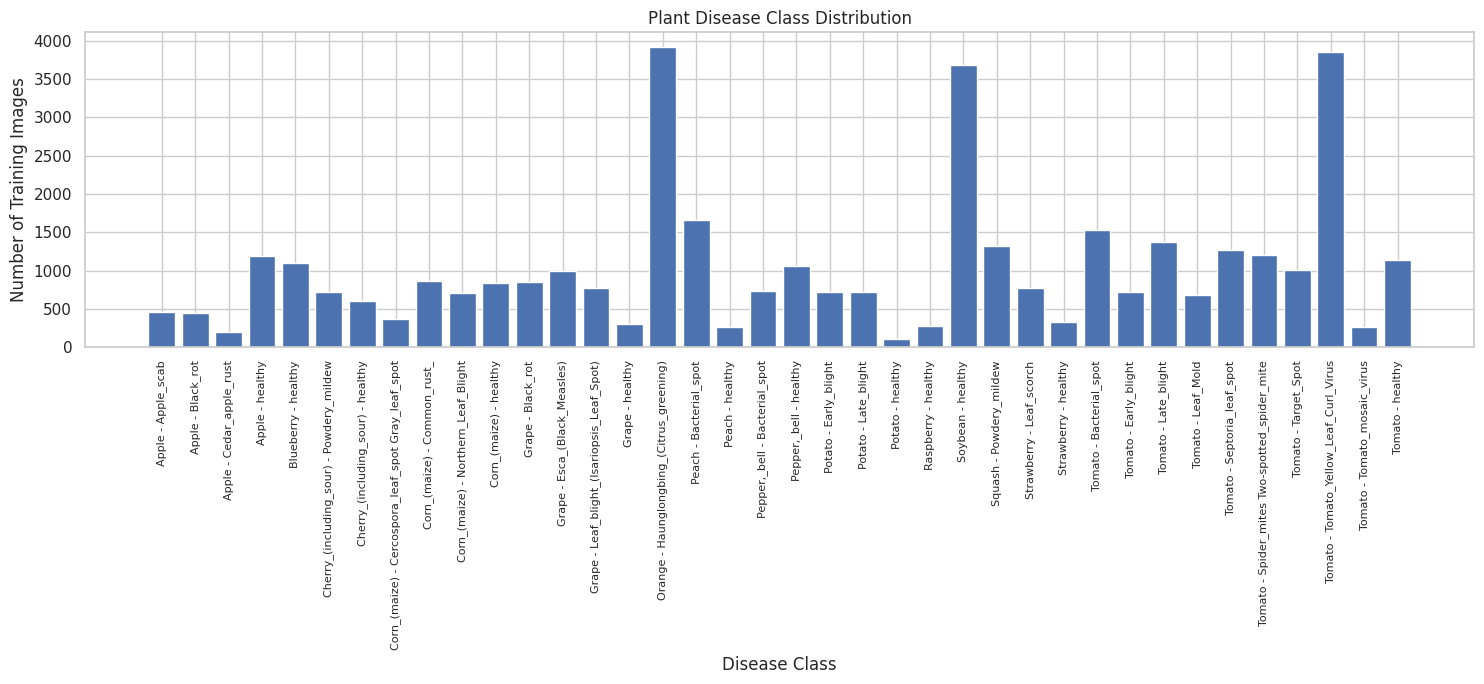

Total training images: 39020


In [ ]:
# Har disease class mein images ki tadaad

class_counts = np.bincount(
    np.array(train_data["class_idx"]),
    minlength=num_classes
)

plt.figure(figsize=(15, 7))
plt.bar(
    range(num_classes),
    class_counts
)

plt.xticks(
    range(num_classes),
    [name.replace("___", " - ") for name in class_names],
    rotation=90,
    fontsize=8
)

plt.title("Plant Disease Class Distribution")
plt.xlabel("Disease Class")
plt.ylabel("Number of Training Images")
plt.tight_layout()
plt.show()

print("Total training images:", int(class_counts.sum()))


CNN model banana

In [ ]:
# Convolutional Neural Network (CNN)
# Data augmentation training ke waqt image variation create
# karti hai, taake model sirf ek image pattern yaad na kare.

from tensorflow.keras import layers, models

model = models.Sequential([
    # Input images
    layers.Input(
        shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
    ),

    # Training images mein halka variation
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10),

    # Feature extraction block 1
    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D(),

    # Feature extraction block 2
    layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D(),

    # Feature extraction block 3
    layers.Conv2D(
        128, (3, 3),
        activation="relu",
        padding="same"
    ),
    layers.MaxPooling2D(),

    # Feature extraction block 4
    layers.Conv2D(
        128, (3, 3),
        activation="relu",
        padding="same"
    ),

    # Features ko compact vector mein convert karna
    layers.GlobalAveragePooling2D(),

    # Overfitting kam karne ke liye dropout
    layers.Dropout(0.35),

    # Final output: har disease class ki probability
    layers.Dense(
        num_classes,
        activation="softmax"
    )
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Model ki layers aur parameters dekhna
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 160, 160, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 20, 20, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │         4,902 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 245,734 (959.90 KB)

 Trainable params: 245,734 (959.90 KB)

 Non-trainable params: 0 (0.00 B)

Model training

In [12]:
# CNN ko train karna
# EarlyStopping unnecessary epochs se bachata hai.
# ModelCheckpoint best validation model save karta hai.

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

callbacks = [
    # Validation loss improve na ho to training rokna
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    # Best model save karna
    ModelCheckpoint(
        "best_plantguard.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    # Zaroorat par learning rate kam karna
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=1
    )
]

# 12 epochs tak training; EarlyStopping pehle bhi rok sakta hai
history = model.fit(
    ds_train,
    validation_data=ds_val,
    epochs=12,
    callbacks=callbacks
)


Epoch 1/12
   1220/Unknown 105s 77ms/step - accuracy: 0.2395 - loss: 2.8880

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()



Epoch 1: val_loss improved from None to 1.69444, saving model to best_plantguard.keras

Epoch 1: finished saving model to best_plantguard.keras
1220/1220 ━━━━━━━━━━━━━━━━━━━━ 112s 83ms/step - accuracy: 0.3262 - loss: 2.4668 - val_accuracy: 0.5113 - val_loss: 1.6944 - learning_rate: 0.0010
Epoch 2/12
1219/1220 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.5666 - loss: 1.4774
Epoch 2: val_loss improved from 1.69444 to 1.09876, saving model to best_plantguard.keras

Epoch 2: finished saving model to best_plantguard.keras
1220/1220 ━━━━━━━━━━━━━━━━━━━━ 139s 84ms/step - accuracy: 0.6064 - loss: 1.3257 - val_accuracy: 0.6716 - val_loss: 1.0988 - learning_rate: 0.0010
Epoch 3/12
1219/1220 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.6875 - loss: 1.0550
Epoch 3: val_loss did not improve from 1.09876
1220/1220 ━━━━━━━━━━━━━━━━━━━━ 141s 113ms/step - accuracy: 0.7040 - loss: 0.9907 - val_accuracy: 0.6774 - val_loss: 1.1180 - learning_rate: 0.0010
Epoch 4/12
1219/1220 ━━━━━━━━━━━━━━━━━━━━ 0s

Accuracy aur loss graphs

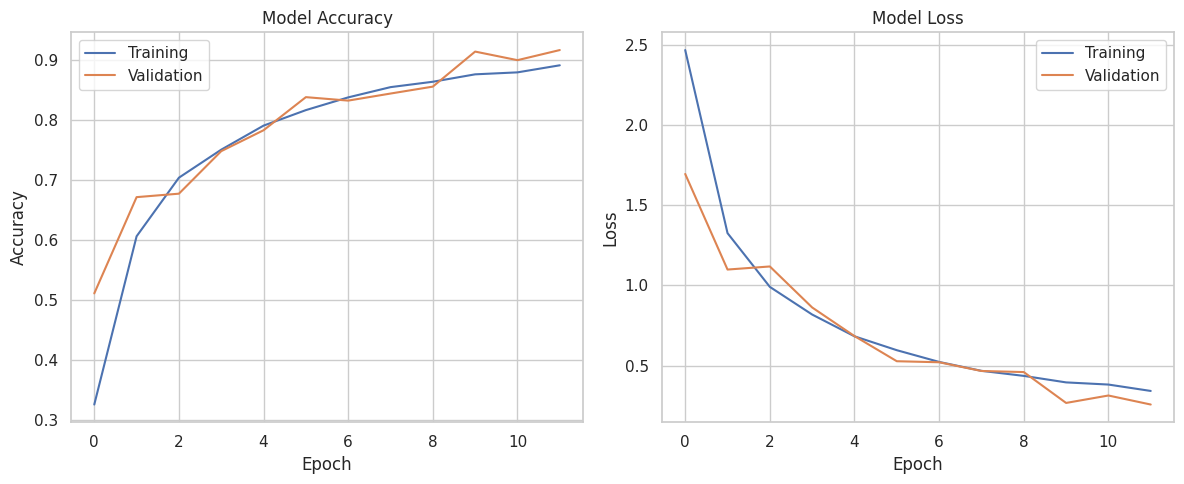

In [13]:
# Training performance graphs
# Accuracy aur loss se training progress samajh aayegi

plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


Test dataset par evaluation

In [14]:
#Unseen test images par final evaluation


test_loss, test_accuracy = model.evaluate(
    ds_test,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")


343/343 ━━━━━━━━━━━━━━━━━━━━ 19s 56ms/step - accuracy: 0.9136 - loss: 0.2743
Test Loss: 0.2743
Test Accuracy: 91.36%


Classification report aur confusion matrix

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab      0.802     0.821     0.811       123
                                 Apple___Black_rot      0.774     0.968     0.860       124
                          Apple___Cedar_apple_rust      1.000     0.800     0.889        55
                                   Apple___healthy      0.936     0.812     0.869       324
                               Blueberry___healthy      0.985     0.960     0.973       278
          Cherry_(including_sour)___Powdery_mildew      0.975     0.944     0.960       252
                 Cherry_(including_sour)___healthy      0.856     0.994     0.920       179
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot      0.941     0.777     0.851       103
                       Corn_(maize)___Common_rust_      0.979     1.000     0.990       238
               Corn_(maize)___Northern_Leaf_Blight      0.887     0.959     0.9

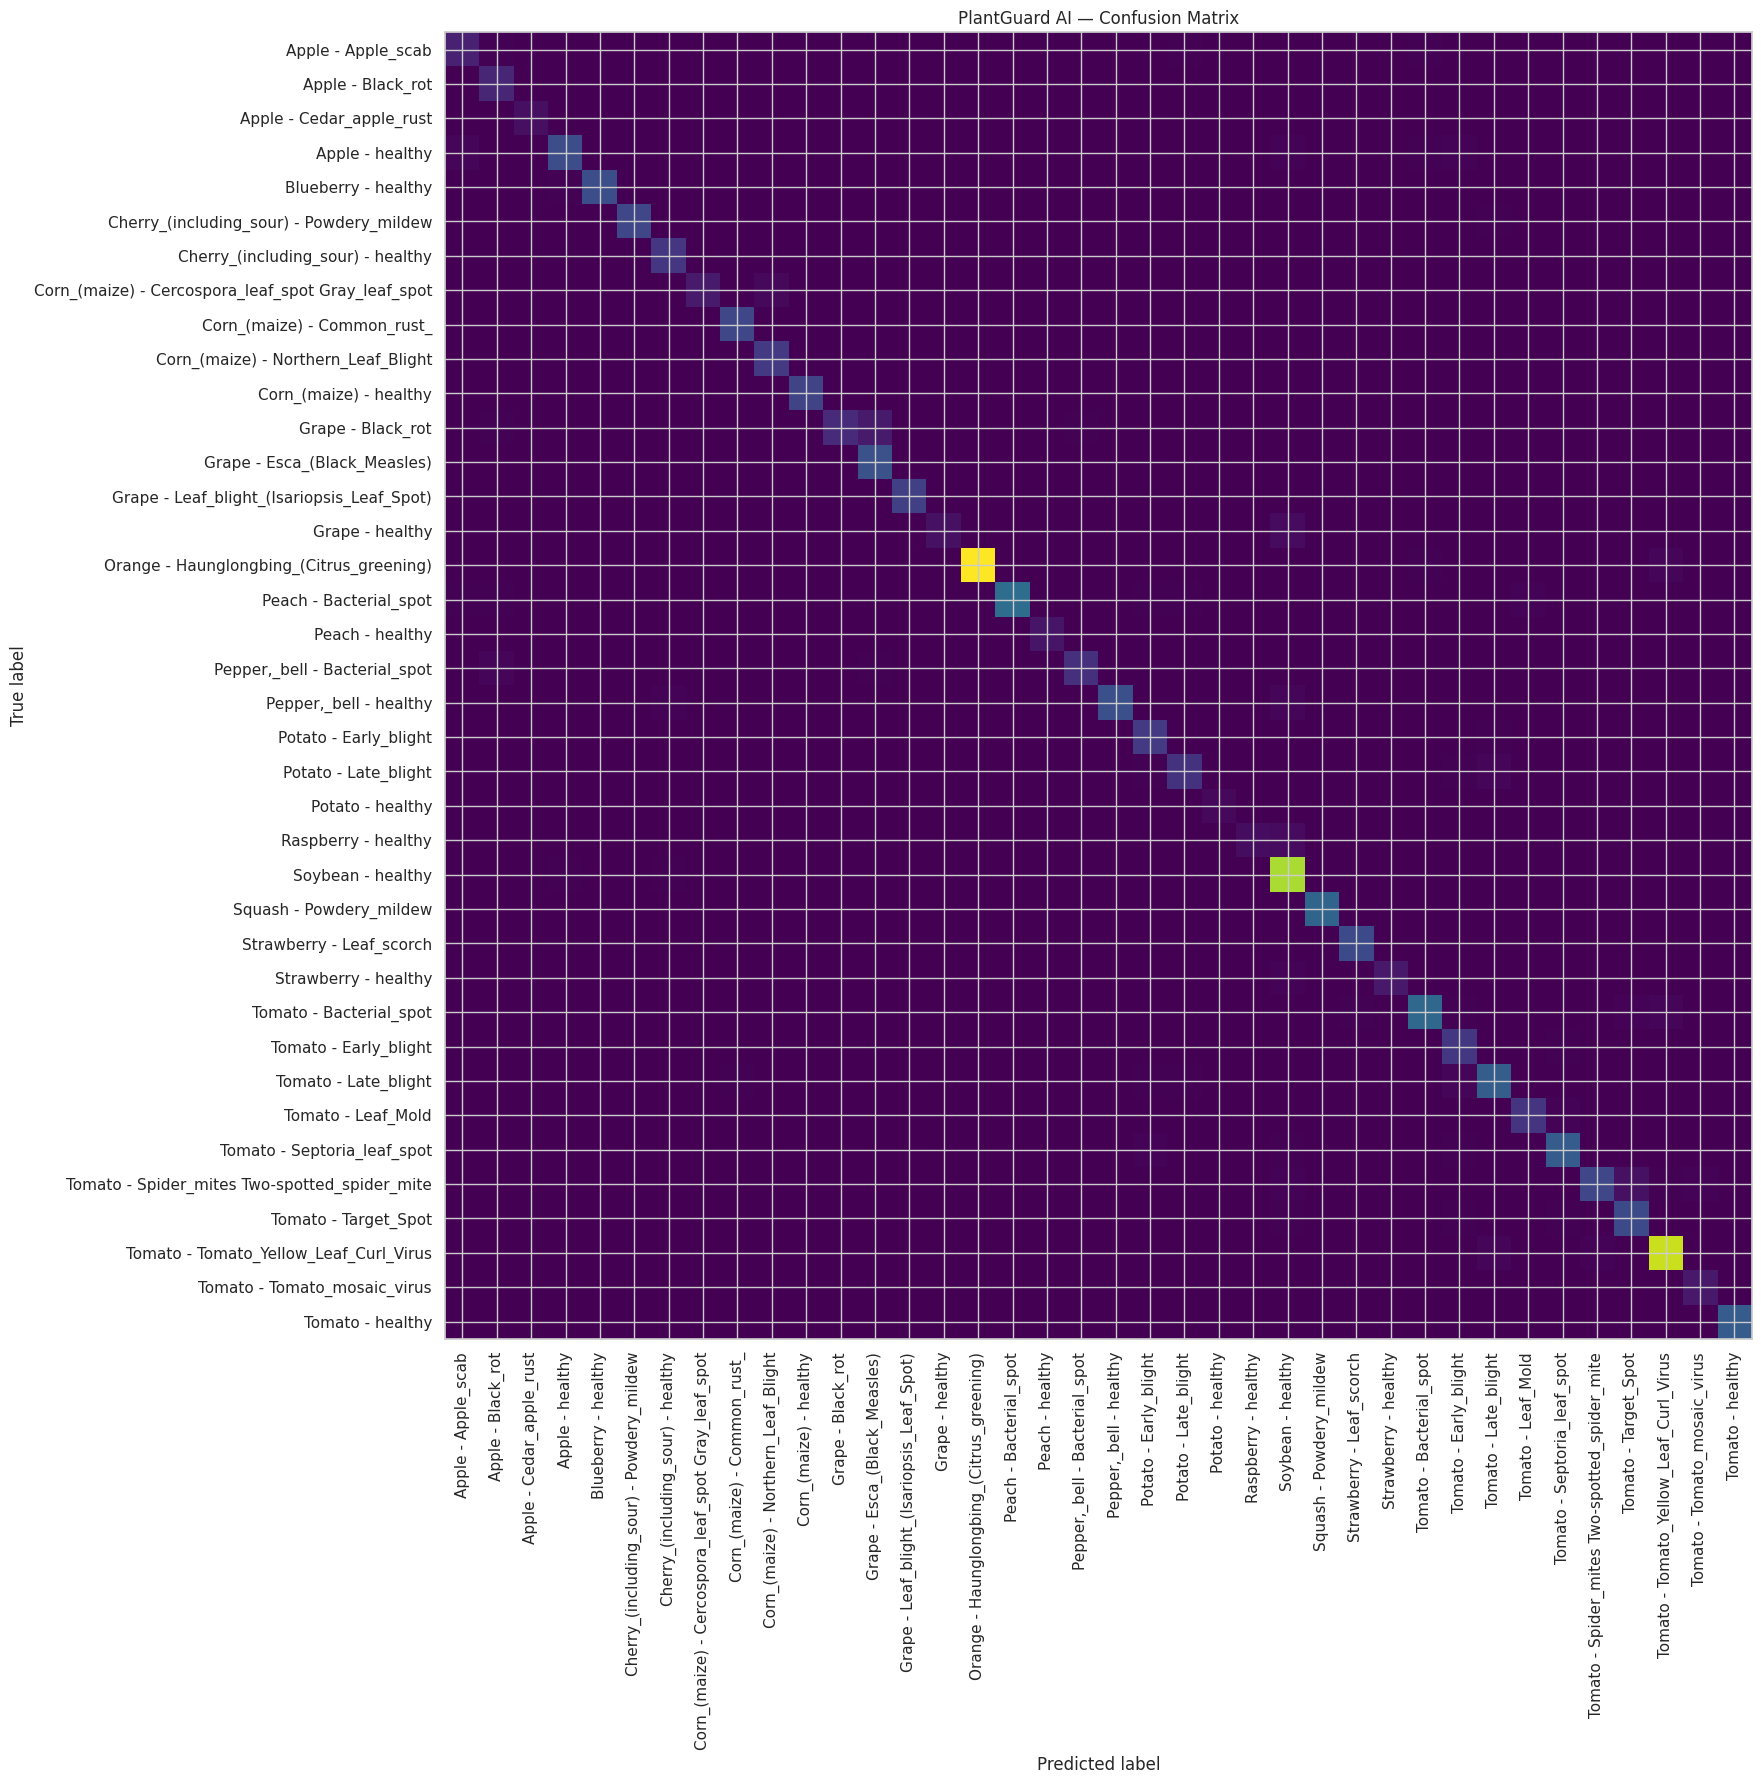

In [15]:
#  Har class ki performance check karna
# Precision, recall aur F1-score calculate honge.

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Model ki predictions aur actual labels collect karna
y_true = []
y_pred = []

for images, labels in ds_test:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy().tolist())
    y_pred.extend(
        np.argmax(predictions, axis=1).tolist()
    )

# Classification report
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(num_classes)),
        target_names=class_names,
        zero_division=0,
        digits=3
    )
)

# Confusion matrix: 38 classes hone ki wajah se figure bara rakhen
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(num_classes))
)

fig, ax = plt.subplots(figsize=(18, 18))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        name.replace("___", " - ")
        for name in class_names
    ]
)

display_cm.plot(
    ax=ax,
    xticks_rotation=90,
    include_values=False,
    colorbar=False
)

plt.title("PlantGuard AI — Confusion Matrix")
plt.tight_layout()
plt.show()


Apni image upload karke prediction

Saving images (4).jfif to images (4).jfif
Uploaded image: images (4).jfif


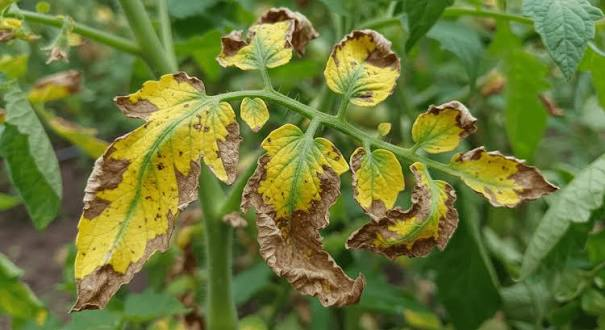


Top predictions:
Pepper,_bell___Bacterial_spot — 99.78%
Peach___Bacterial_spot — 0.16%
Corn_(maize)___Common_rust_ — 0.03%

Predicted class: Pepper,_bell___Bacterial_spot
Confidence: 99.78%


In [16]:

# ============================================================
# STEP 12: User ki plant leaf image predict karna
# ============================================================

from google.colab import files
from PIL import Image
from IPython.display import display

# Computer se leaf image upload karna
uploaded = files.upload()

for filename in uploaded.keys():
    # Image open aur RGB mein convert karna
    image = Image.open(filename).convert("RGB")

    print("Uploaded image:", filename)
    display(image)

    # Model ke input ke mutabiq resize karna
    resized_image = image.resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    )

    # Pixel values normalize karke batch dimension add karna
    image_array = np.asarray(
        resized_image,
        dtype=np.float32
    ) / 255.0

    image_array = np.expand_dims(
        image_array,
        axis=0
    )

    # Prediction probabilities
    probabilities = model.predict(
        image_array,
        verbose=0
    )[0]

    # Top 3 predictions nikalna
    top_indices = np.argsort(probabilities)[-3:][::-1]

    print("\nTop predictions:")
    for index in top_indices:
        print(
            class_names[index],
            "—",
            f"{probabilities[index] * 100:.2f}%"
        )

    best_index = int(np.argmax(probabilities))

    print("\nPredicted class:", class_names[best_index])
    print(
        "Confidence:",
        f"{probabilities[best_index] * 100:.2f}%"
    )


Attractive web interface with Gradio

In [17]:
#  Gradio web interface
# User leaf image upload karega aur model prediction show karega.

%pip install -q gradio


In [18]:

import gradio as gr

def predict_plant_disease(image):
    # Empty input handle karna
    if image is None:
        return {"Please upload a plant image": 1.0}

    # Image ko RGB format mein convert karna
    image = image.convert("RGB")
    image = image.resize((IMAGE_SIZE, IMAGE_SIZE))

    # Model input prepare karna
    arr = np.asarray(
        image,
        dtype=np.float32
    ) / 255.0

    arr = np.expand_dims(arr, axis=0)

    # Prediction probabilities
    probabilities = model.predict(
        arr,
        verbose=0
    )[0]

    # Top 5 classes ka result
    top_indices = np.argsort(probabilities)[-5:][::-1]

    results = {
        class_names[int(i)]: float(probabilities[i])
        for i in top_indices
    }

    return results

# Clean and simple demo interface
demo = gr.Interface(
    fn=predict_plant_disease,
    inputs=gr.Image(
        type="pil",
        label="Upload a Plant Leaf Image"
    ),
    outputs=gr.Label(
        num_top_classes=5,
        label="Plant Disease Predictions"
    ),
    title="PlantGuard AI",
    description=(
        "AI-powered plant leaf classification. "
        "Upload a clear leaf image to see the model's top predictions."
    ),
    theme=gr.themes.Soft()
)

# Shareable temporary demo URL
demo.launch(share=True)


/usr/local/lib/python3.13/dist-packages/gradio/interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e6a473471408e73511.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Model aur labels save karna

In [19]:
# Trained model aur class labels save karna

# Final model save karna
model.save("plantguard_disease_model.keras")

# Class names save karna
with open("plantguard_labels.json", "w") as file:
    json.dump(class_names, file, indent=4)

# Evaluation results save karna
results = {
    "project": "PlantGuard AI",
    "dataset": "PlantVillage Full",
    "num_classes": int(num_classes),
    "image_size": int(IMAGE_SIZE),
    "test_accuracy": float(test_accuracy),
    "test_loss": float(test_loss)
}

with open("plantguard_results.json", "w") as file:
    json.dump(results, file, indent=4)

print("Model, labels and evaluation results saved!")


Model, labels and evaluation results saved!


Files download karna

In [20]:
# Model files apne computer par download karna

from google.colab import files

files.download("plantguard_disease_model.keras")
files.download("plantguard_labels.json")
files.download("plantguard_results.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Final Report**

Project Title: Plant Disease Detection Using CNN

Abstract: Plant leaf images se disease categories predict karne wala image classification system.

Problem Statement: Plant diseases ki visual identification mein madad dene ke liye automated classification model banana.

Objectives: Image preprocessing, CNN training, disease classification aur performance evaluation.

Dataset: PlantVillage Full, 54,304 images aur 38 classes.

Datasets at Hugging Face

Tools: Google Colab, Python, TensorFlow/Keras, Hugging Face Datasets, Matplotlib, scikit-learn aur Gradio.

Methodology: Dataset loading, preprocessing, CNN training, validation, testing aur image prediction.

Results: Apni actual test accuracy, classification report aur confusion matrix include karna.

Limitations: PlantVillage images plain backgrounds mein hain; real farms, different lighting aur phone-camera images par performance kam ho sakti hai.

Conclusion and Future Work: Real-world images par testing, transfer learning aur mobile deployment.